# Tugas Pertemuan 12 Object Detection dengan YOLOv8

### 1 Install library
Ultralytics dipakai untuk model YOLOv8 dan kagglehub untuk download dataset dari Kaggle

In [1]:
!pip install -q ultralytics kagglehub

### 2 Download dataset dari Kaggle
Dataset Traffic Signs Detection berisi 4969 gambar rambu lalu lintas dengan 15 kelas dan sudah dalam format YOLO

In [2]:
import kagglehub, glob, os, yaml
root = kagglehub.dataset_download("pkdarabi/cardetection")
yaml_path = glob.glob(f"{root}/**/data.yaml", recursive=True)[0]
data_dir = os.path.dirname(yaml_path)
cfg = yaml.safe_load(open(yaml_path))
print(cfg["nc"], cfg["names"])

Using Colab cache for faster access to the 'cardetection' dataset.
15 ['Green Light', 'Red Light', 'Speed Limit 10', 'Speed Limit 100', 'Speed Limit 110', 'Speed Limit 120', 'Speed Limit 20', 'Speed Limit 30', 'Speed Limit 40', 'Speed Limit 50', 'Speed Limit 60', 'Speed Limit 70', 'Speed Limit 80', 'Speed Limit 90', 'Stop']


### 3 Atur path dataset
Path bawaan di data yaml belum sesuai jadi ditulis ulang ke folder train valid dan test

In [3]:
cfg.update(path=data_dir, train="train/images", val="valid/images", test="test/images")
yaml.safe_dump(cfg, open("data.yaml", "w"))
for s in ["train", "valid", "test"]:
    print(s, len(os.listdir(f"{data_dir}/{s}/images")))

train 3530
valid 801
test 638


### 4 Training YOLOv8
YOLOv8 termasuk one stage detector jadi kotak lokasi dan kelas objek diprediksi sekaligus dalam satu kali proses

Model pakai bobot pretrained COCO lalu dilatih ulang ke dataset rambu selama 20 epoch

In [4]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.train(data="data.yaml", epochs=20, imgsz=640, batch=16, seed=42)
run = model.trainer.save_dir

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.

Contoh batch training beserta label kotaknya lalu grafik loss dan mAP tiap epoch

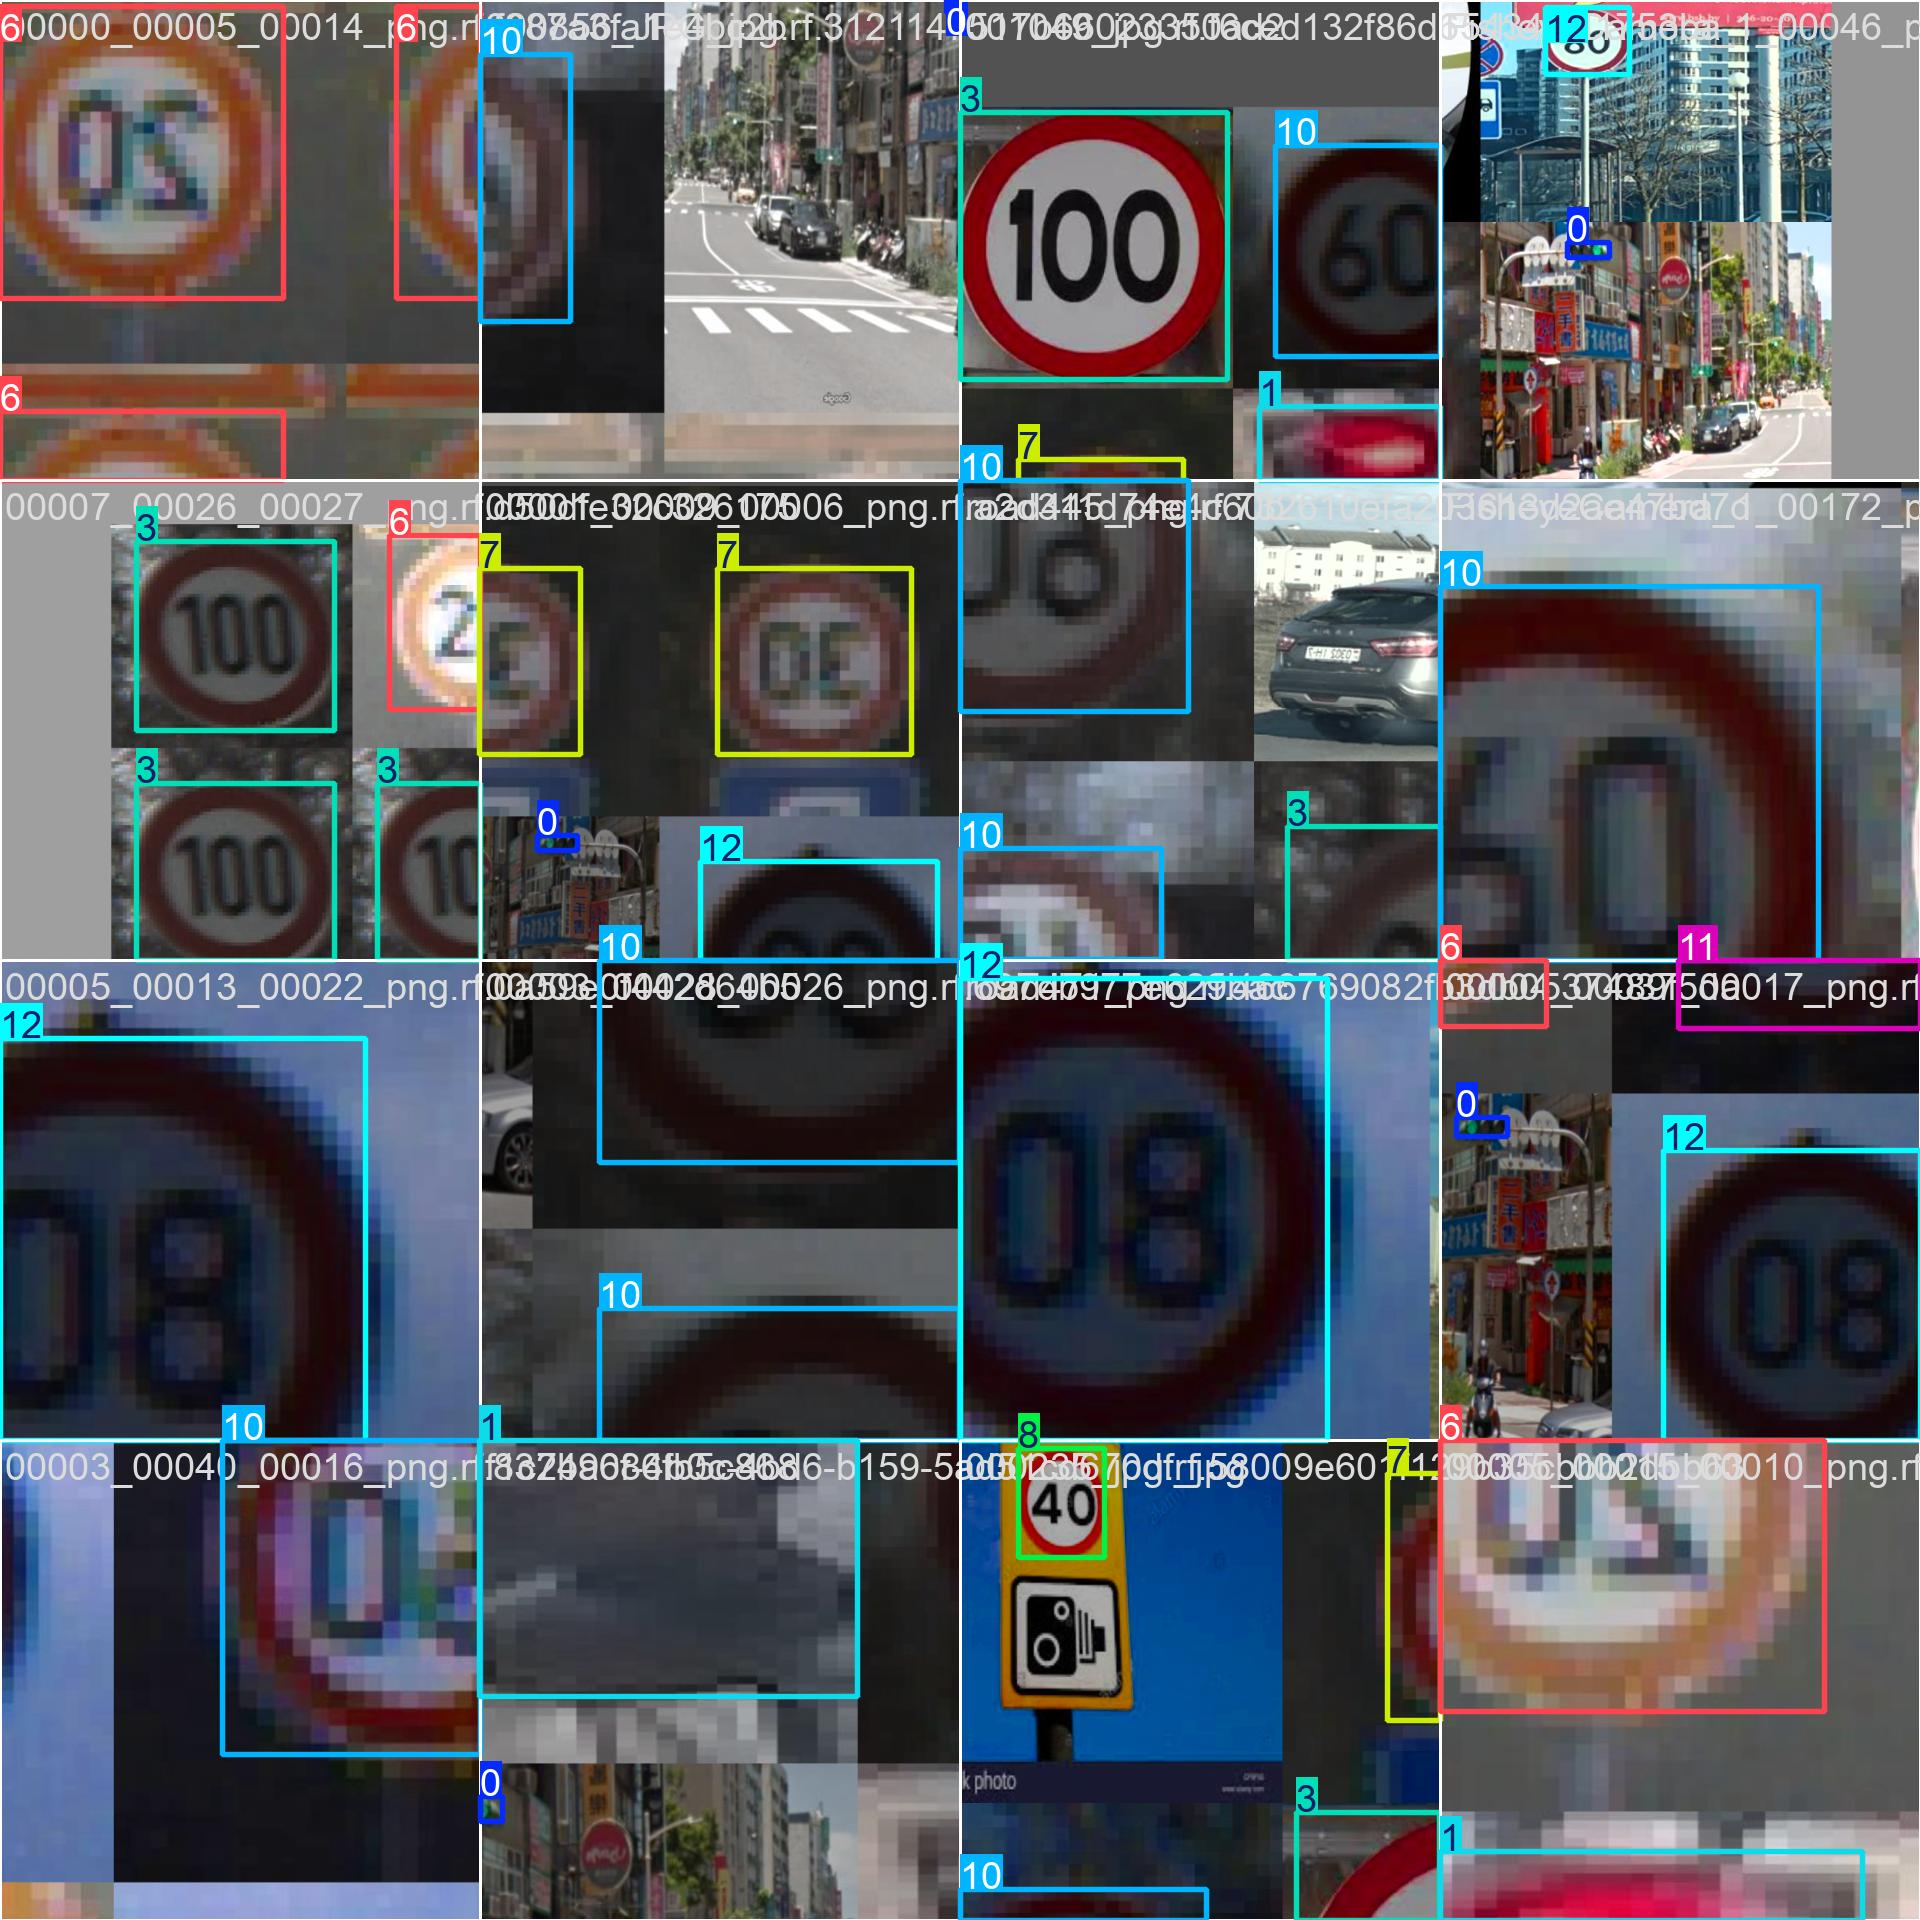

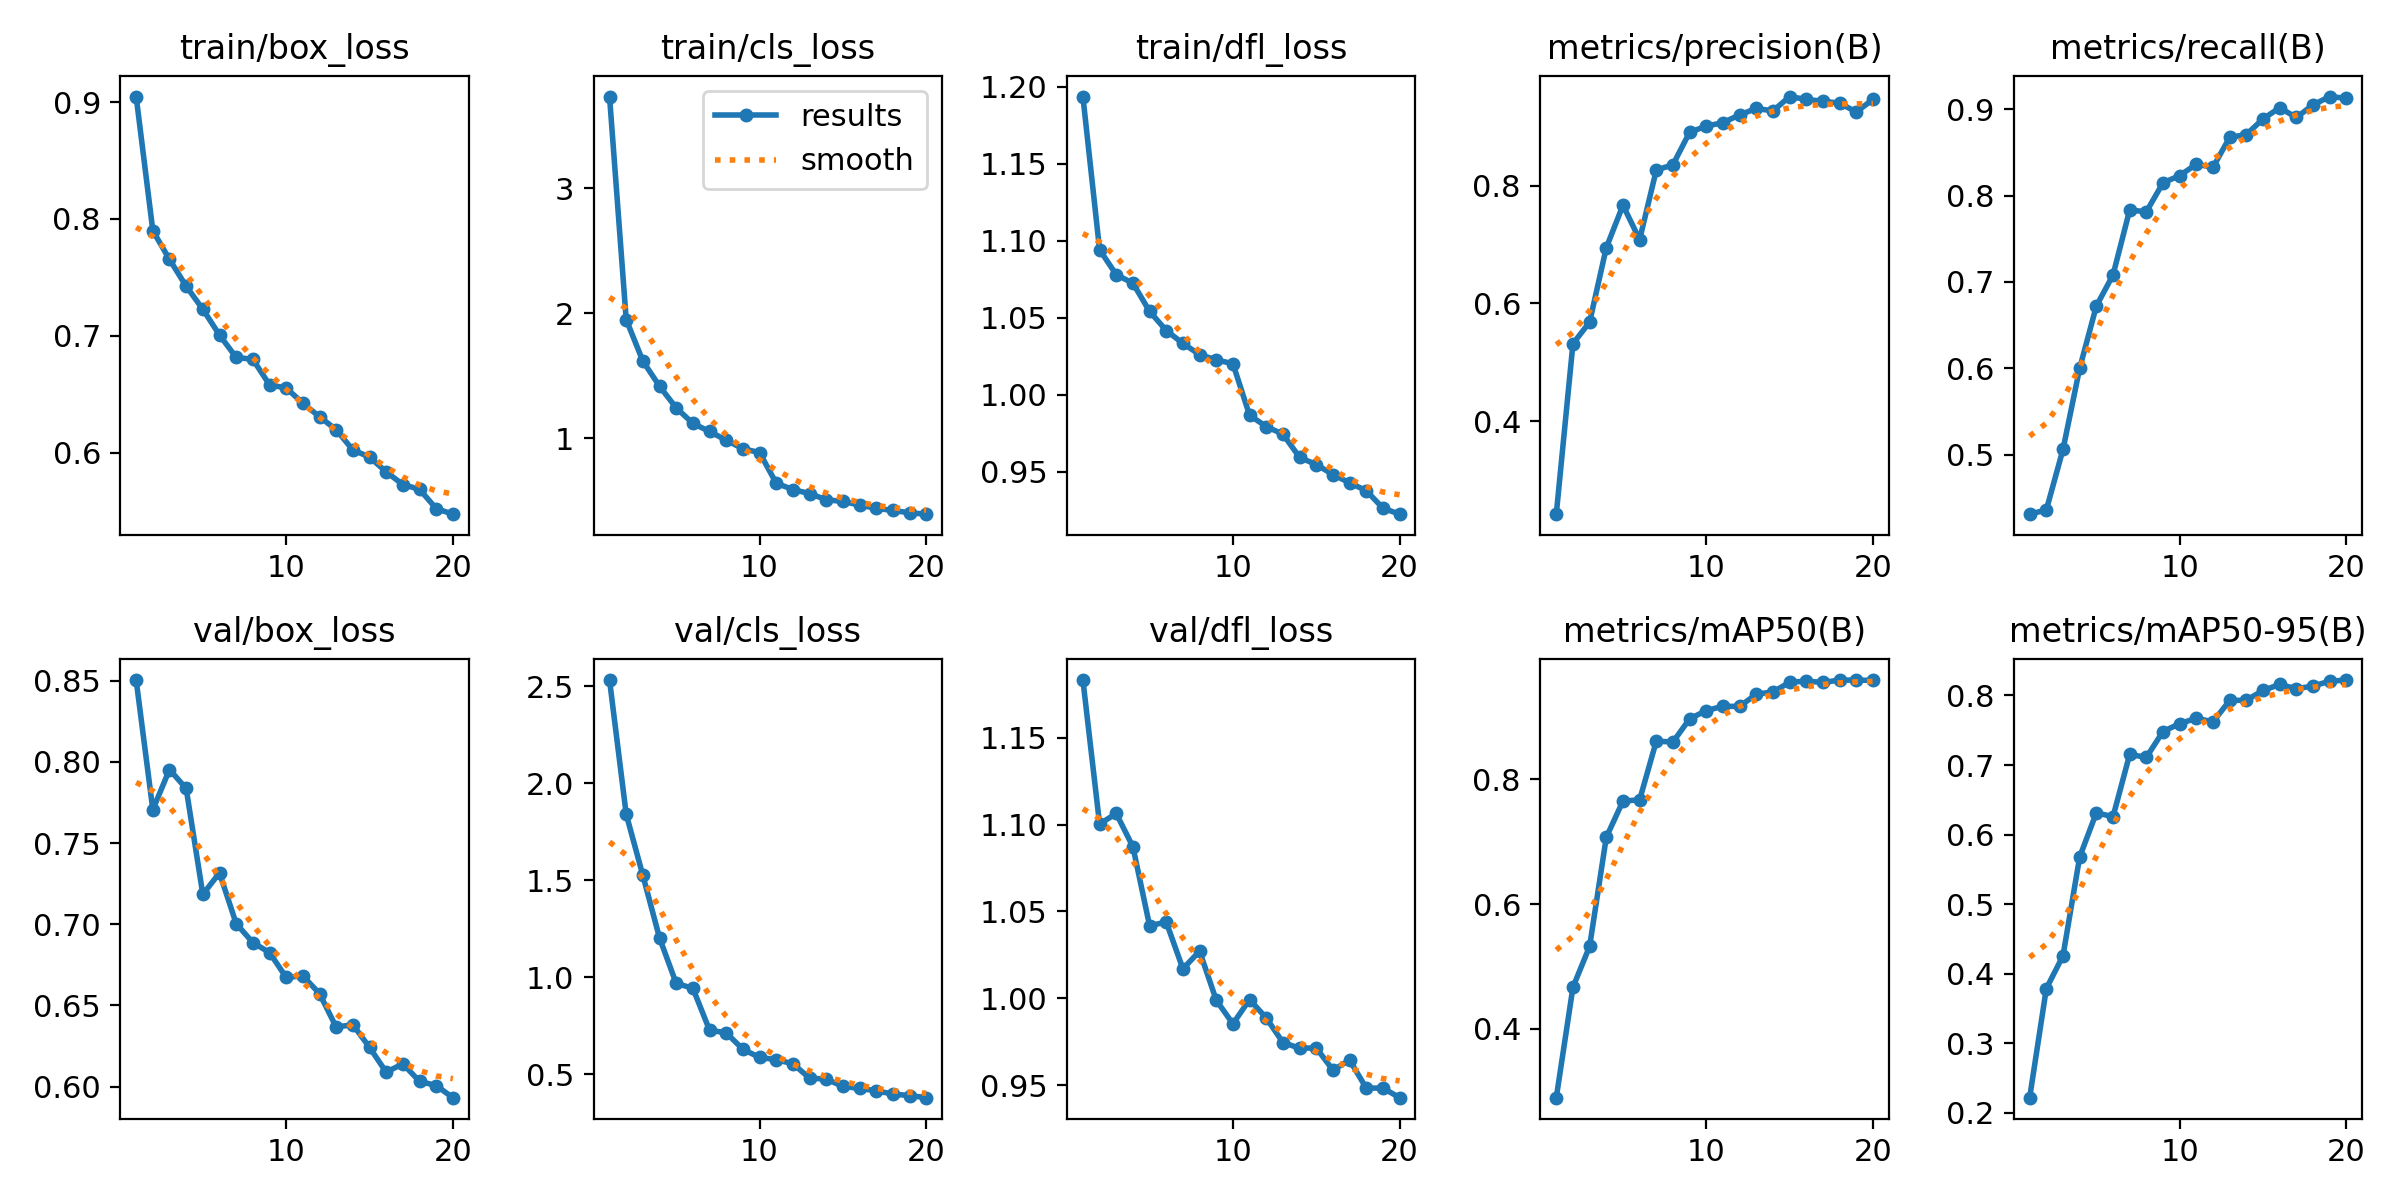

In [5]:
from IPython.display import Image, display
display(Image(f"{run}/train_batch0.jpg", width=600))
display(Image(f"{run}/results.png", width=900))

### 5 Evaluasi mAP di data test
IoU adalah seberapa besar kotak prediksi menempel dengan kotak asli

AP adalah luas area di bawah kurva precision recall untuk satu kelas dan mAP adalah rata rata AP dari semua kelas

mAP50 artinya prediksi dianggap benar kalau IoU minimal 50 persen sedangkan mAP50 95 adalah rata rata mAP dari IoU 50 sampai 95 persen

In [6]:
best = YOLO(f"{run}/weights/best.pt")
m = best.val(data="data.yaml", split="test")
print(f"Precision : {m.box.mp:.4f}")
print(f"Recall    : {m.box.mr:.4f}")
print(f"mAP50     : {m.box.map50:.4f}")
print(f"mAP50-95  : {m.box.map:.4f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.9 ms, read: 1.8±0.9 MB/s, size: 21.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/cardetection/car/test/labels... 638 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 638/638 41.9it/s 15.2s
WARNING ⚠️ val: Cache directory /kaggle/input/cardetection/car/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 5.0it/s 8.1s
                   all        638        770      0.887       0.89      0.939      0.793
           Green Light         77        110      0.847        0.8      0.903      0.532
             Red Light         71         94      0.786 

AP tiap kelas

In [7]:
import pandas as pd
pd.DataFrame({
    "Kelas": [best.names[i] for i in m.box.ap_class_index],
    "AP50": m.box.ap50,
    "AP50-95": m.box.ap,
}).round(4)

,Kelas,AP50,AP50-95
0,Green Light,0.9027,0.5320
1,Red Light,0.8011,0.4748
2,Speed Limit 10,0.8630,0.6706
3,Speed Limit 100,0.9869,0.8599
4,Speed Limit 110,0.8889,0.7938
5,Speed Limit 120,0.9692,0.8714
6,Speed Limit 20,0.9730,0.8819
7,Speed Limit 30,0.9453,0.8402
8,Speed Limit 40,0.9895,0.8892
9,Speed Limit 50,0.9112,0.8246


Kurva precision recall dan confusion matrix

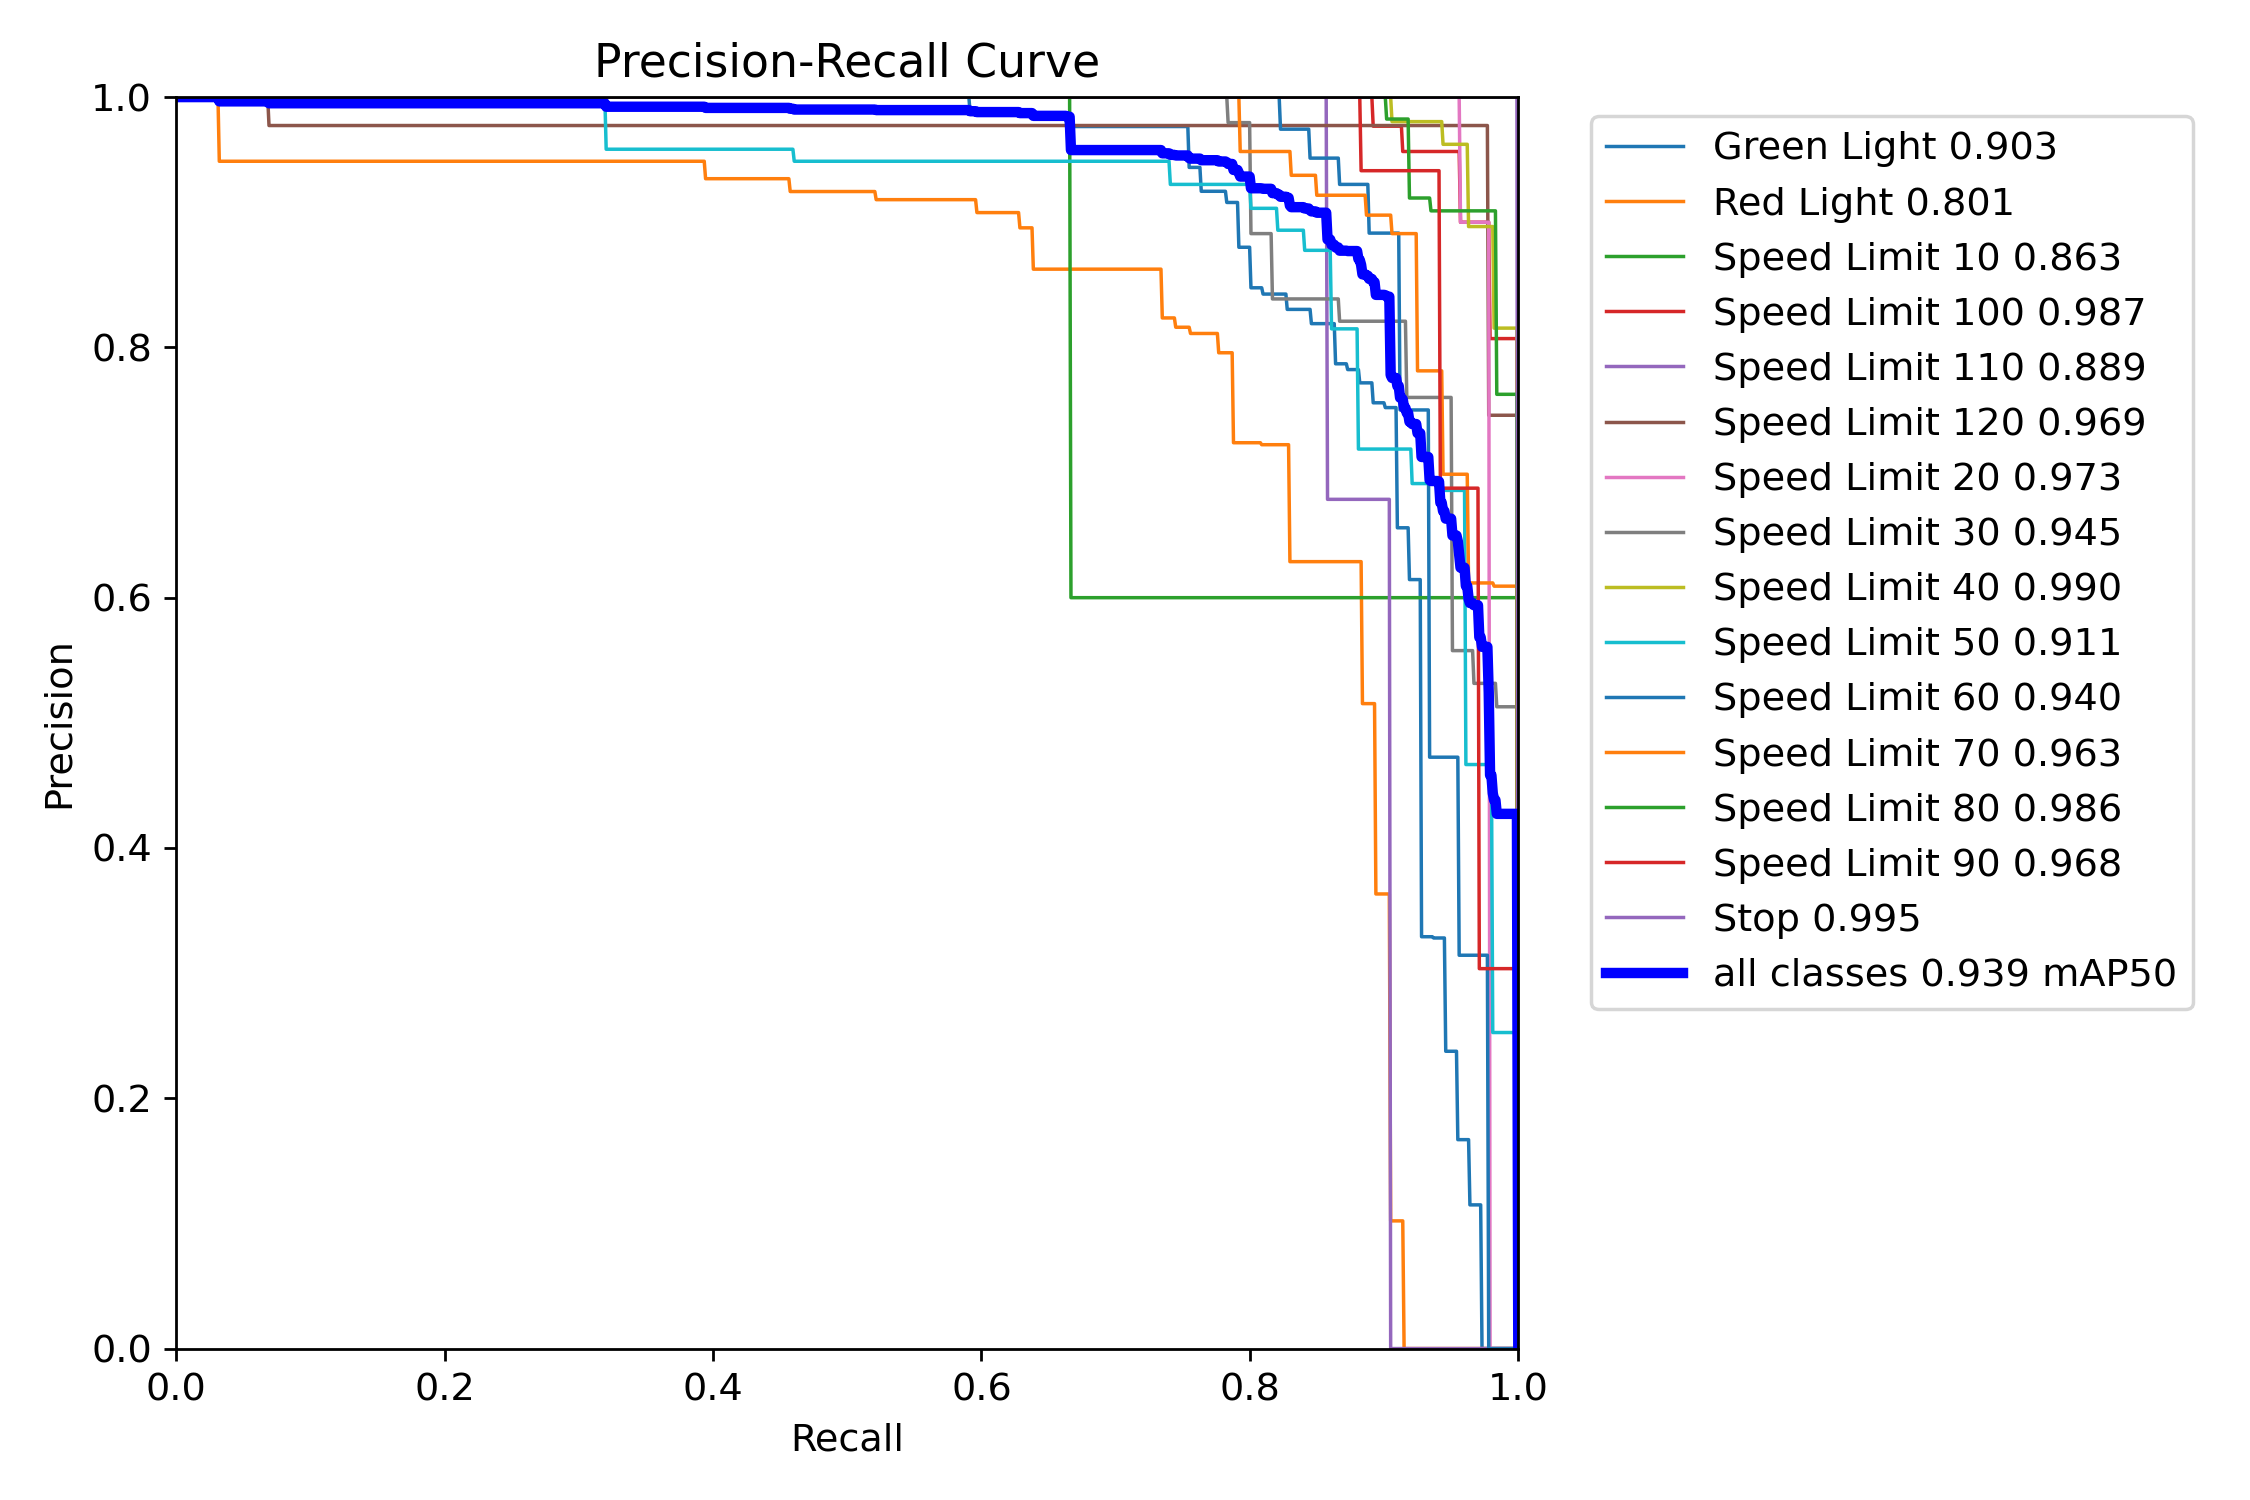

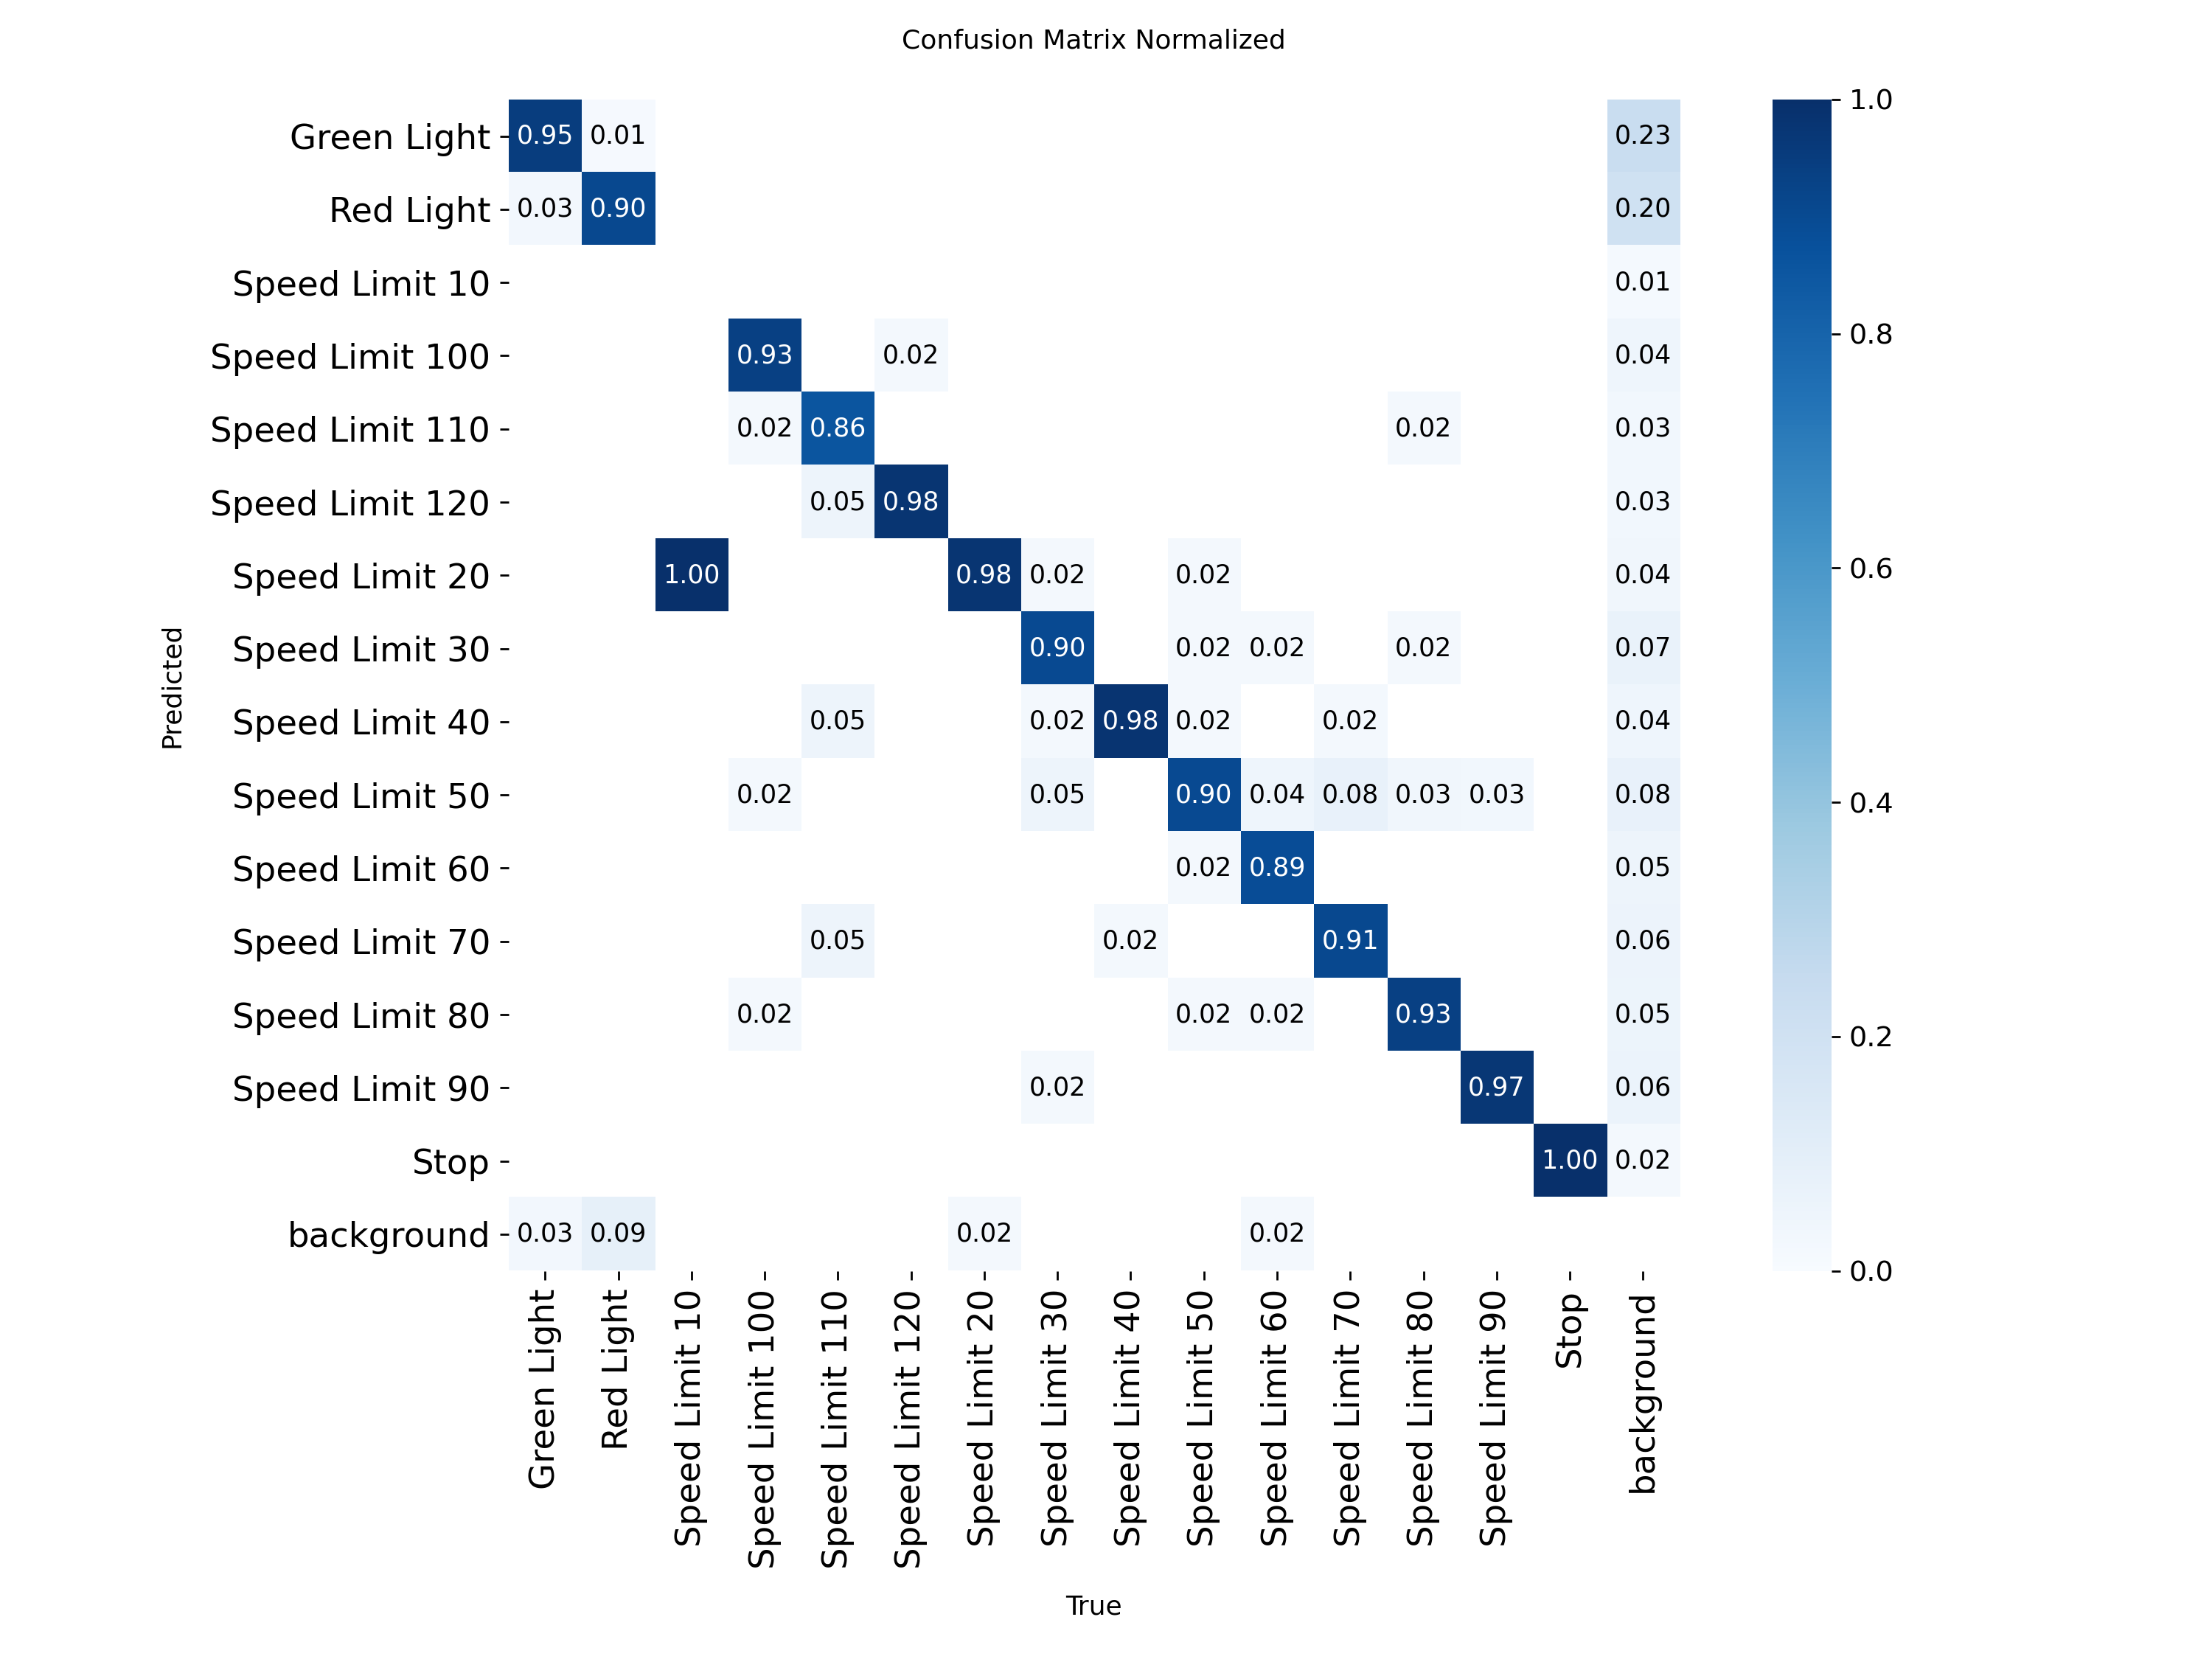

In [8]:
display(Image(glob.glob(f"{m.save_dir}/*PR_curve.png")[0], width=800))
display(Image(f"{m.save_dir}/confusion_matrix_normalized.png", width=800))

### 6 Hasil deteksi di gambar test

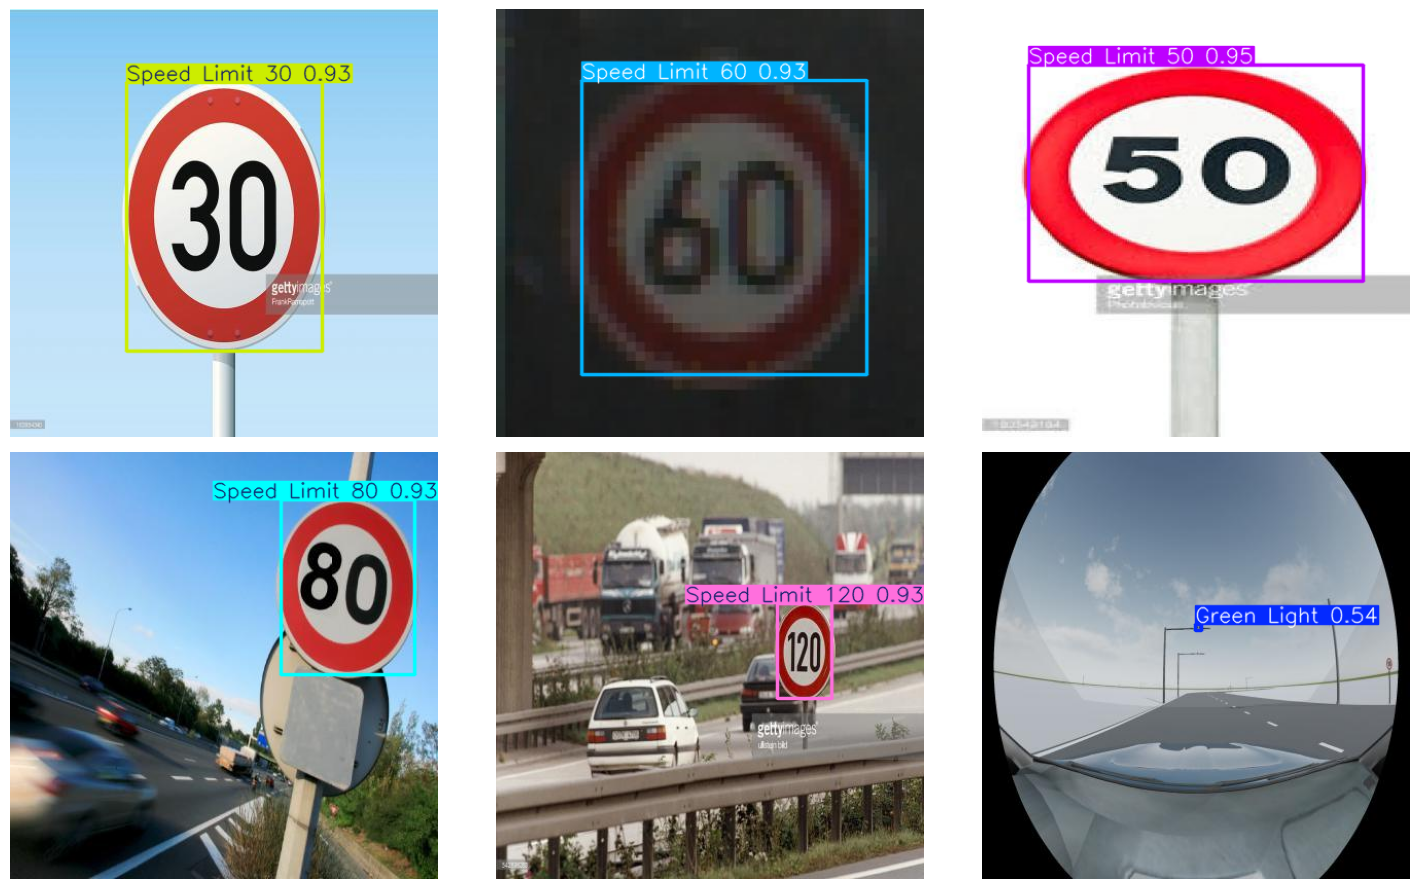

In [10]:
import matplotlib.pyplot as plt
imgs = sorted(glob.glob(f"{data_dir}/test/images/*"))[::100][:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, r in zip(axes.flat, best.predict(imgs, conf=0.5, verbose=False)):
    ax.imshow(r.plot()[:, :, ::-1])
    ax.axis("off")
plt.tight_layout()
plt.show()

### 7 Kesimpulan
Model YOLOv8n yang dilatih 20 epoch mendapat hasil di data test sebagai berikut

Precision sekitar 89 persen

Recall sekitar 89 persen

mAP50 sekitar 94 persen

mAP50 95 sekitar 79 persen

Kelas Stop paling mudah dideteksi dengan AP50 hampir 100 persen karena bentuk dan warnanya khas

Kelas Red Light dan Green Light paling rendah dengan AP50 sekitar 80 dan 90 persen karena objek lampu ukurannya kecil dan bentuknya mirip satu sama lain

Kelas Speed Limit 10 cuma punya 3 objek di data test jadi nilainya kurang bisa dijadikan patokan